# Proyecto final · Fase 4 — Semana 3

## Visualización y comunicación de resultados

**MCDI500 · Programación para la Ciencia de Datos**
**Caso de trabajo: predicción de accidente cerebrovascular (*stroke*)**

---

Este cuaderno cierra el proyecto. No vuelve a limpiar ni a transformar: **recibe los
cuatro artefactos que dejó la Fase 3**, construye a partir de ellos una copia con las
unidades originales y responde con figuras las preguntas declaradas en la Fase 1.

| Fase | Cuaderno | Qué entrega a la siguiente |
|---|---|---|
| F1 | `F1/S1_F1_Definicion.ipynb` | Problema, preguntas, entorno y ficha del conjunto |
| F2 | `F2/S1_F2_Preprocesamiento.ipynb` | Decisiones de limpieza justificadas con cifras |
| F3 | `F3/S2_F3_NucleoAlgoritmico_Eficiencia_POO.ipynb` | Pipeline en clases y cuatro artefactos en `data/processed/` |
| **F4** | **este cuaderno** | Figuras, hallazgos y evidencia para el informe y el video |

**Cómo usarlo.** Ejecuten antes F1, F2 y F3, en ese orden. Este cuaderno se detiene con un
mensaje claro si no encuentra los artefactos de la Fase 3: no genera datos de reemplazo,
porque un gráfico hecho con datos inventados no responde ninguna pregunta.

**El principio que ordena la fase.** Un gráfico responde una pregunta. Si una figura no
responde alguna pregunta u objetivo declarado en la Fase 1, no pertenece al informe. Y si
una pregunta no tiene figura que la responda, el trabajo está incompleto.

## 1. Entorno y ubicación del proyecto

La primera comprobación es la misma de las fases anteriores: que el cuaderno corra con el
intérprete del proyecto y que encuentre la raíz aunque Jupyter lo abra dentro de `F4/`.

In [1]:
import os
import sys
import json
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
np.random.seed(SEMILLA)

print("Python     :", sys.executable)
print("Entorno    :", "virtual" if sys.prefix != sys.base_prefix else "AVISO: Python del sistema")
print("pandas     :", pd.__version__)
print("NumPy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)

Python     : /usr/local/bin/python3
Entorno    : AVISO: Python del sistema
pandas     : 3.0.5
NumPy      : 2.5.3
matplotlib : 3.11.2


In [2]:
def localizar_raiz(inicio=None):
    """Devuelve la raíz del proyecto.

    Jupyter abre el kernel en la carpeta del cuaderno (F4), no en la raíz. Si la
    carpeta de trabajo es una carpeta de fase, la raíz es la carpeta superior.
    """
    actual = Path(inicio or Path.cwd()).resolve()
    return actual.parent if actual.name in {"F1", "F2", "F3", "F4"} else actual


RAIZ = localizar_raiz()
DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_CRUDO = RAIZ / "data" / "raw"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_DOCS = RAIZ / "docs"

# La raíz debe estar en la ruta de búsqueda para importar los módulos de src/,
# exactamente como en la Fase 3
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import comunicacion as com
from src.medicion import medir

print("Raíz del proyecto :", RAIZ)
print("Artefactos de F3  :", DIR_PROCESADO.relative_to(RAIZ))
print("Figuras de F4     :", DIR_FIGURAS.relative_to(RAIZ))

Raíz del proyecto : /tmp/claude-0/x/s3build/proyecto
Artefactos de F3  : data/processed
Figuras de F4     : F4/figuras


### Estilo de las figuras

Se define una sola vez. El color tiene **función**, no decoración: el granate marca lo que
la figura quiere que se mire, y el resto queda en gris o azul. Así el lector encuentra el
hallazgo sin buscarlo.

In [3]:
GRANATE = "#AC212E"     # el dato que se quiere destacar
AZUL = "#06304A"        # dato de contexto o comparación
TINTA = "#0A1526"       # texto
HIELO = "#D7E3EE"       # fondos y bandas de referencia
GRIS = "#8A94A0"        # lo secundario

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (8, 4.4),
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10.5,
    "axes.labelcolor": TINTA,
    "axes.edgecolor": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "legend.frameon": False,
    "font.size": 10,
})


def porcentaje(eje):
    """Formatea el eje como porcentaje: el lector no debe convertir proporciones."""
    eje.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))


def nota_fuente(figura, texto="Fuente: Stroke Prediction Dataset (fedesoriano, Kaggle). n = 5.110."):
    # Debajo de la etiqueta del eje x, para no taparla
    figura.text(0.01, -0.07, texto, fontsize=8, color=GRIS, ha="left", va="top")


def pct(proporcion, decimales=1):
    """Porcentaje con coma decimal, como se escribe en el informe en castellano."""
    return f"{proporcion * 100:.{decimales}f} %".replace(".", ",")


def miles(numero):
    """Entero con punto como separador de miles: 4.861 y no 4,861."""
    return f"{int(numero):,}".replace(",", ".")

---
## 2. Lo que la Fase 3 entregó

### 2.1 Carga de los cuatro artefactos

`cargar_artefactos` vive en `src/comunicacion.py`. Si falta un archivo, se detiene y dice
qué cuaderno ejecutar. No hay alternativa silenciosa.

In [4]:
artefactos = com.cargar_artefactos(DIR_PROCESADO)

for nombre, tabla in artefactos.items():
    print(f"{nombre:<14} {tabla.shape[0]:>5} filas x {tabla.shape[1]:>2} columnas")

entrenamiento   4088 filas x 22 columnas
prueba          1022 filas x 22 columnas
diccionario       22 filas x  4 columnas
parametros        12 filas x  3 columnas


### 2.2 Verificar el contrato antes de usarlo

La Fase 3 prometió un esquema. Antes de graficar se comprueba que lo cumplió: mismas
columnas en entrenamiento y prueba, en el orden del diccionario, sin nulos, y con las
continuas efectivamente escaladas en el entrenamiento (media 0 y desviación 1).

In [5]:
entrenamiento = artefactos["entrenamiento"]
prueba = artefactos["prueba"]
diccionario = artefactos["diccionario"]
parametros = com.leer_parametros(artefactos["parametros"])

CONTINUAS = [p[len("EscaladorEstandar("):-1] for p in parametros if p.startswith("EscaladorEstandar(")]
OBJETIVO = "stroke"

assert list(entrenamiento.columns) == list(diccionario["columna"]), "El entrenamiento no sigue el diccionario"
assert list(prueba.columns) == list(entrenamiento.columns), "Entrenamiento y prueba difieren en esquema"
assert entrenamiento.isna().sum().sum() == 0 and prueba.isna().sum().sum() == 0, "Hay nulos en los artefactos"
assert np.allclose(entrenamiento[CONTINUAS].mean(), 0, atol=1e-9), "Las continuas no están centradas"
assert np.allclose(entrenamiento[CONTINUAS].std(), 1, atol=1e-9), "Las continuas no están escaladas"

print("Contrato de la Fase 3: cumplido")
print("Continuas escaladas :", CONTINUAS)
print("Pasos registrados   :", len(parametros))
print(f"Media de 'age' en prueba (escalada): {prueba['age'].mean():+.4f}  (no es 0: el escalador no aprendió de prueba)")

Contrato de la Fase 3: cumplido
Continuas escaladas : ['age', 'avg_glucose_level', 'bmi']
Pasos registrados   : 12
Media de 'age' en prueba (escalada): -0.0528  (no es 0: el escalador no aprendió de prueba)


### 2.3 La copia interpretable

Un gráfico con la edad en desviaciones estándar no se entiende. Para comunicar se
construye una **copia** con las unidades originales, aplicando la inversa exacta del
escalamiento con los parámetros que aprendió la Fase 3:

$$x = z \cdot \sigma_{\text{entrenamiento}} + \mu_{\text{entrenamiento}}$$

y se vuelven a juntar las columnas 0/1 en una sola columna con la categoría. Los
artefactos de la Fase 3 **no se modifican**: la copia es solo para comunicar.

In [6]:
entrenamiento_legible = com.copia_interpretable(entrenamiento, parametros)
prueba_legible = com.copia_interpretable(prueba, parametros)

# Para describir la población se usan ambos conjuntos: describir no es evaluar un
# modelo, así que no hay fuga de información en juntarlos
legible = pd.concat([entrenamiento_legible, prueba_legible], ignore_index=True)

print(f"Copia interpretable: {legible.shape[0]} filas x {legible.shape[1]} columnas")
legible[["age", "avg_glucose_level", "bmi", "gender", "smoking_status", "stroke"]].describe(include="all").round(2)

Copia interpretable: 5110 filas x 11 columnas


,age,avg_glucose_level,bmi,gender,smoking_status,stroke
count,5110.00,5110.00,5110.00,5110,5110,5110.00
unique,NaN,NaN,NaN,3,4,NaN
top,NaN,NaN,NaN,Female,never smoked,NaN
freq,NaN,NaN,NaN,2994,1892,NaN
mean,43.23,106.15,28.86,NaN,NaN,0.05
std,22.61,45.28,7.70,NaN,NaN,0.22
min,0.08,55.12,10.30,NaN,NaN,0.00
25%,25.00,77.24,23.80,NaN,NaN,0.00
50%,45.00,91.88,28.10,NaN,NaN,0.00
75%,61.00,114.09,32.80,NaN,NaN,0.00


### 2.4 La verificación que más rinde: contra el archivo original

Comprobar la copia con el mismo código que la produjo sería circular. La verificación
independiente es contra el **archivo original** de `data/raw`: si la inversa es correcta,
al juntar entrenamiento y prueba deben aparecer exactamente los mismos valores de edad y
glucosa, y las mismas frecuencias de cada categoría.

El IMC es la excepción esperada: la Fase 3 imputó sus 201 faltantes con la mediana del
entrenamiento, así que debe coincidir con el original **después** de aplicar esa misma
imputación.

In [7]:
original = pd.read_csv(DIR_CRUDO / "healthcare-dataset-stroke-data.csv")
mediana_bmi = parametros["ImputadorMediana(bmi)"]["mediana"]

comprobaciones = {
    "Mismo número de registros": len(legible) == len(original),
    "Edad idéntica al original": np.allclose(np.sort(legible["age"]), np.sort(original["age"])),
    "Glucosa idéntica al original": np.allclose(np.sort(legible["avg_glucose_level"]),
                                                np.sort(original["avg_glucose_level"])),
    "IMC idéntico tras la imputación de F3": np.allclose(np.sort(legible["bmi"]),
                                                          np.sort(original["bmi"].fillna(mediana_bmi))),
    "Mismos casos de ACV": int(legible[OBJETIVO].sum()) == int(original[OBJETIVO].sum()),
}
for columna in ["gender", "work_type", "smoking_status", "Residence_type", "ever_married"]:
    comprobaciones[f"Frecuencias de {columna}"] = (
        legible[columna].value_counts().sort_index().equals(original[columna].value_counts().sort_index())
    )

for control, resultado in comprobaciones.items():
    print(f"[{'OK' if resultado else 'FALLA'}] {control}")
assert all(comprobaciones.values()), "La copia interpretable no coincide con el original"

[OK] Mismo número de registros
[OK] Edad idéntica al original
[OK] Glucosa idéntica al original
[OK] IMC idéntico tras la imputación de F3
[OK] Mismos casos de ACV
[OK] Frecuencias de gender
[OK] Frecuencias de work_type
[OK] Frecuencias de smoking_status
[OK] Frecuencias de Residence_type
[OK] Frecuencias de ever_married


---
## 3. Las preguntas de la Fase 1, respondidas con figuras

La Fase 1 dejó tres preguntas y un objetivo general: **caracterizar los factores asociados
al accidente cerebrovascular**. Cada figura de esta sección responde una de ellas, y su
título dice el hallazgo, no el tipo de gráfico.

| Figura | Pregunta u objetivo que responde |
|---|---|
| 1 | ¿Qué proporción de la muestra corresponde a la clase positiva? |
| 2 | ¿Qué variables concentran los faltantes y qué implica imputarlas? |
| 3 | Objetivo general: el factor con mayor asociación, la edad |
| 4 | Objetivo general: hipertensión, separando el efecto de la edad |
| 5 | Objetivo general: glucosa, con umbrales clínicos |
| 6 | Advertencia: una asociación que no es un factor de riesgo |

### Figura 1 · La clase positiva es escasa

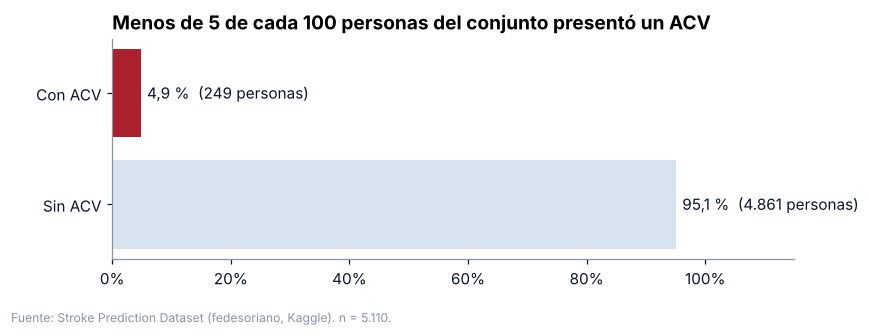

Tasa global: 4,87 %  (IC 95 %: 4,32 % a 5,50 %)


In [8]:
casos = int(legible[OBJETIVO].sum())
total = len(legible)
tasa_global = casos / total
inferior, superior = com.intervalo_wilson(casos, total)

figuras = {}
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(["Sin ACV", "Con ACV"], [1 - tasa_global, tasa_global], color=[HIELO, GRANATE])
for y, valor, n in [(0, 1 - tasa_global, total - casos), (1, tasa_global, casos)]:
    ax.text(valor + 0.01, y, f"{pct(valor, 1)}  ({miles(n)} personas)", va="center", color=TINTA)
porcentaje(ax.xaxis)
ax.set_xlim(0, 1.15)
ax.set_title("Menos de 5 de cada 100 personas del conjunto presentó un ACV")
nota_fuente(fig)
figuras["fig1_clase_positiva"] = fig
plt.show()

print(f"Tasa global: {pct(tasa_global, 2)}  (IC 95 %: {pct(inferior, 2)} a {pct(superior, 2)})")

**Lectura.** Con 4,9 % de casos, un modelo que siempre responda «sin ACV» acierta el 95 %
de las veces sin haber aprendido nada. Por eso, si el proyecto llegara a modelar, la
exactitud no serviría como métrica: habría que mirar sensibilidad, precisión o el área
bajo la curva. Para este informe, la consecuencia es más simple: toda tasa por grupo debe
mostrarse con su tamaño y su intervalo, porque con pocos casos la incertidumbre es grande.

### Figura 2 · Los faltantes del IMC no son aleatorios

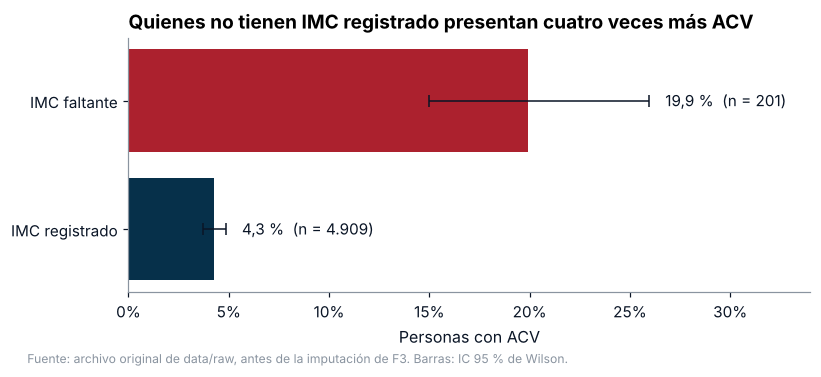

Desviación del IMC: 7.85 con faltantes, 7.70 tras imputar (-2.0%)


In [9]:
original["imc_registrado"] = np.where(original["bmi"].isna(), "IMC faltante", "IMC registrado")
tasas_imc = com.tasa_por_grupo(original, "imc_registrado", OBJETIVO).sort_values("tasa")

fig, ax = plt.subplots(figsize=(8, 3))
colores = [AZUL if g == "IMC registrado" else GRANATE for g in tasas_imc["imc_registrado"]]
ax.barh(tasas_imc["imc_registrado"], tasas_imc["tasa"], color=colores,
        xerr=[tasas_imc["tasa"] - tasas_imc["ic_inferior"], tasas_imc["ic_superior"] - tasas_imc["tasa"]],
        error_kw={"ecolor": TINTA, "capsize": 4, "lw": 1})
for y, (_, fila) in enumerate(tasas_imc.iterrows()):
    ax.text(fila["ic_superior"] + 0.008, y, f"{pct(fila['tasa'], 1)}  (n = {miles(fila['n'])})",
            va="center", color=TINTA)
porcentaje(ax.xaxis)
ax.set_xlim(0, 0.34)
ax.set_xlabel("Personas con ACV")
ax.set_title("Quienes no tienen IMC registrado presentan cuatro veces más ACV")
nota_fuente(fig, "Fuente: archivo original de data/raw, antes de la imputación de F3. Barras: IC 95 % de Wilson.")
figuras["fig2_faltantes_imc"] = fig
plt.show()

desv_original = original["bmi"].std()
desv_imputada = original["bmi"].fillna(mediana_bmi).std()
print(f"Desviación del IMC: {desv_original:.2f} con faltantes, {desv_imputada:.2f} tras imputar ({desv_imputada / desv_original - 1:+.1%})")

**Lectura.** Esta figura responde la primera pregunta de la Fase 1 y obliga a matizar una
decisión de la Fase 3. Imputar con la mediana fue razonable para no perder 201 registros,
pero los faltantes **no son aleatorios**: se concentran en personas con ACV. Al imputarlos
se borra esa señal y la dispersión del IMC baja un 2 %. En el informe debe declararse
como limitación, y una mejora concreta sería agregar al pipeline una columna indicadora
de imputación, como paso nuevo de la clase `ImputadorMediana`.

### Figura 3 · La edad es el factor con mayor asociación

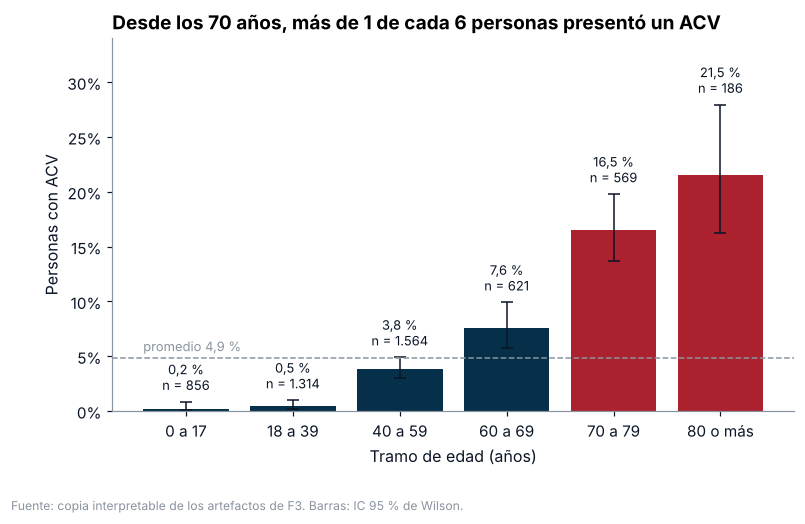

,tramo_edad,n,casos,tasa,ic_inferior,ic_superior
0,0 a 17,856,2,0.0023,0.0006,0.0085
1,18 a 39,1314,6,0.0046,0.0021,0.0099
2,40 a 59,1564,60,0.0384,0.0299,0.0491
3,60 a 69,621,47,0.0757,0.0574,0.0992
4,70 a 79,569,94,0.1652,0.1370,0.1979
5,80 o más,186,40,0.2151,0.1621,0.2795


In [10]:
TRAMOS = [0, 18, 40, 60, 70, 80, 120]
ETIQUETAS = ["0 a 17", "18 a 39", "40 a 59", "60 a 69", "70 a 79", "80 o más"]
legible["tramo_edad"] = pd.cut(legible["age"], TRAMOS, right=False, labels=ETIQUETAS)
tasas_edad = com.tasa_por_grupo(legible, "tramo_edad", OBJETIVO)

fig, ax = plt.subplots()
colores = [GRANATE if t >= 0.15 else AZUL for t in tasas_edad["tasa"]]
ax.bar(tasas_edad["tramo_edad"].astype(str), tasas_edad["tasa"], color=colores,
       yerr=[tasas_edad["tasa"] - tasas_edad["ic_inferior"], tasas_edad["ic_superior"] - tasas_edad["tasa"]],
       error_kw={"ecolor": TINTA, "capsize": 4, "lw": 1})
for x, (_, fila) in enumerate(tasas_edad.iterrows()):
    ax.text(x, fila["ic_superior"] + 0.008, f"{pct(fila['tasa'], 1)}\nn = {miles(fila['n'])}",
            ha="center", va="bottom", fontsize=8.5, color=TINTA)
ax.axhline(tasa_global, color=GRIS, lw=1, ls="--")
ax.text(-0.4, tasa_global + 0.006, f"promedio {pct(tasa_global, 1)}", color=GRIS, fontsize=8.5)
porcentaje(ax.yaxis)
ax.set_ylim(0, 0.34)
ax.set_xlabel("Tramo de edad (años)")
ax.set_ylabel("Personas con ACV")
ax.set_title("Desde los 70 años, más de 1 de cada 6 personas presentó un ACV")
nota_fuente(fig, "Fuente: copia interpretable de los artefactos de F3. Barras: IC 95 % de Wilson.")
figuras["fig3_edad"] = fig
plt.show()

tasas_edad.round(4)

**Lectura.** La tasa crece con cada tramo: bajo el 0,5 % antes de los 40 años y sobre el
16 % desde los 70. Los intervalos de los tramos jóvenes son estrechos porque hay muchas
personas, y el de 80 o más es ancho porque hay solo 186. Es el hallazgo central del
proyecto, y también el que condiciona la lectura de todos los demás, como muestra la
figura siguiente.

### Figura 4 · La hipertensión se asocia al ACV incluso a igual edad

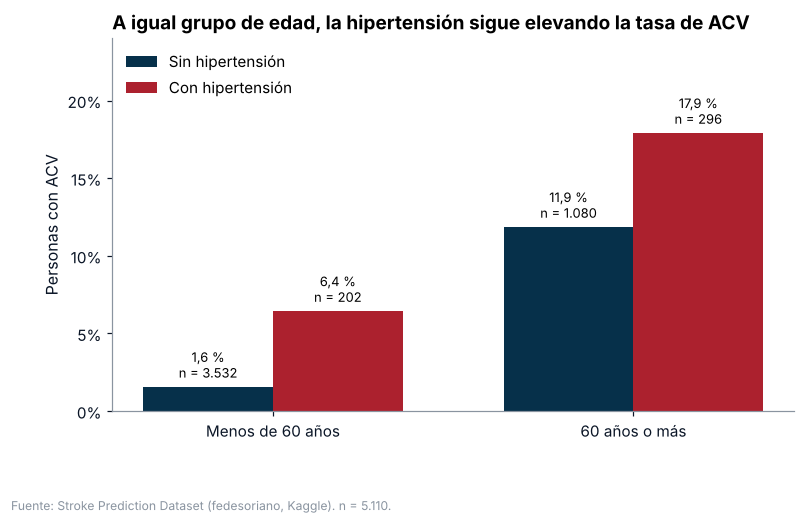

Comparación sin separar por edad: 13,3 % frente a 4,0 % (3.3 veces)
Mediana de edad: {'Con hipertensión': 63.0, 'Sin hipertensión': 42.0}


In [11]:
legible["grupo_edad"] = np.where(legible["age"] >= 60, "60 años o más", "Menos de 60 años")
legible["hipertension"] = legible["hypertension"].map({0: "Sin hipertensión", 1: "Con hipertensión"})

cruda = com.tasa_por_grupo(legible, "hipertension", OBJETIVO).set_index("hipertension")["tasa"]
estratos = (legible.groupby(["grupo_edad", "hipertension"], observed=True)[OBJETIVO]
            .agg(["mean", "size"]).rename(columns={"mean": "tasa", "size": "n"}).reset_index())

fig, ax = plt.subplots()
grupos = ["Menos de 60 años", "60 años o más"]
ancho = 0.36
for desplazamiento, categoria, color in [(-ancho / 2, "Sin hipertensión", AZUL), (ancho / 2, "Con hipertensión", GRANATE)]:
    datos = estratos[estratos["hipertension"] == categoria].set_index("grupo_edad").loc[grupos]
    posiciones = np.arange(len(grupos)) + desplazamiento
    ax.bar(posiciones, datos["tasa"], width=ancho, color=color, label=categoria)
    for x, tasa, n in zip(posiciones, datos["tasa"], datos["n"]):
        ax.text(x, tasa + 0.004, f"{pct(tasa, 1)}\nn = {miles(n)}", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(range(len(grupos)), grupos)
porcentaje(ax.yaxis)
ax.set_ylim(0, 0.24)
ax.set_ylabel("Personas con ACV")
ax.legend(loc="upper left")
ax.set_title("A igual grupo de edad, la hipertensión sigue elevando la tasa de ACV")
nota_fuente(fig)
figuras["fig4_hipertension_por_edad"] = fig
plt.show()

print(f"Comparación sin separar por edad: {pct(cruda['Con hipertensión'], 1)} frente a {pct(cruda['Sin hipertensión'], 1)} "
      f"({cruda['Con hipertensión'] / cruda['Sin hipertensión']:.1f} veces)")
print("Mediana de edad:", legible.groupby("hipertension")["age"].median().to_dict())

**Lectura.** Sin separar por edad, la hipertensión parece triplicar la tasa (13,3 % frente
a 4,0 %). Pero las personas hipertensas son bastante mayores (mediana de 63 frente a 42
años), así que parte de esa diferencia es en realidad efecto de la edad. Al comparar dentro
de cada grupo de edad la diferencia se reduce, **pero no desaparece**: es una asociación
que resiste el control por la variable de confusión más evidente. Aun así, es una
asociación en datos observacionales, no una relación causal demostrada.

### Figura 5 · La glucosa en rango de diabetes casi triplica la tasa

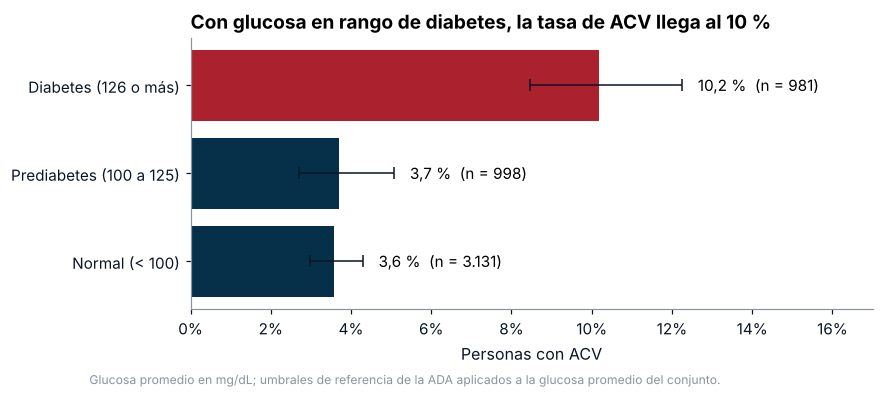

In [12]:
UMBRALES = [0, 100, 126, 1000]
CATEGORIAS = ["Normal (< 100)", "Prediabetes (100 a 125)", "Diabetes (126 o más)"]
legible["glucosa_clinica"] = pd.cut(legible["avg_glucose_level"], UMBRALES, right=False, labels=CATEGORIAS)
tasas_glucosa = com.tasa_por_grupo(legible, "glucosa_clinica", OBJETIVO)

fig, ax = plt.subplots(figsize=(8, 3.2))
colores = [GRANATE if c.startswith("Diabetes") else AZUL for c in tasas_glucosa["glucosa_clinica"].astype(str)]
ax.barh(tasas_glucosa["glucosa_clinica"].astype(str), tasas_glucosa["tasa"], color=colores,
        xerr=[tasas_glucosa["tasa"] - tasas_glucosa["ic_inferior"], tasas_glucosa["ic_superior"] - tasas_glucosa["tasa"]],
        error_kw={"ecolor": TINTA, "capsize": 4, "lw": 1})
for y, (_, fila) in enumerate(tasas_glucosa.iterrows()):
    ax.text(fila["ic_superior"] + 0.004, y, f"{pct(fila['tasa'], 1)}  (n = {miles(fila['n'])})", va="center")
porcentaje(ax.xaxis)
ax.set_xlim(0, 0.17)
ax.set_xlabel("Personas con ACV")
ax.set_title("Con glucosa en rango de diabetes, la tasa de ACV llega al 10 %")
nota_fuente(fig, "Glucosa promedio en mg/dL; umbrales de referencia de la ADA aplicados a la glucosa promedio del conjunto.")
figuras["fig5_glucosa"] = fig
plt.show()

**Lectura.** Entre glucosa normal y prediabetes la tasa prácticamente no cambia (3,6 % y
3,7 %, con intervalos que se superponen). El salto ocurre en el rango de diabetes, con
10,2 %. Una advertencia de método: la variable del conjunto es la glucosa **promedio**, no
una glucosa en ayunas, por lo que los umbrales clínicos se usan como referencia de lectura
y no como diagnóstico.

### Figura 6 · Una asociación que no es un factor de riesgo

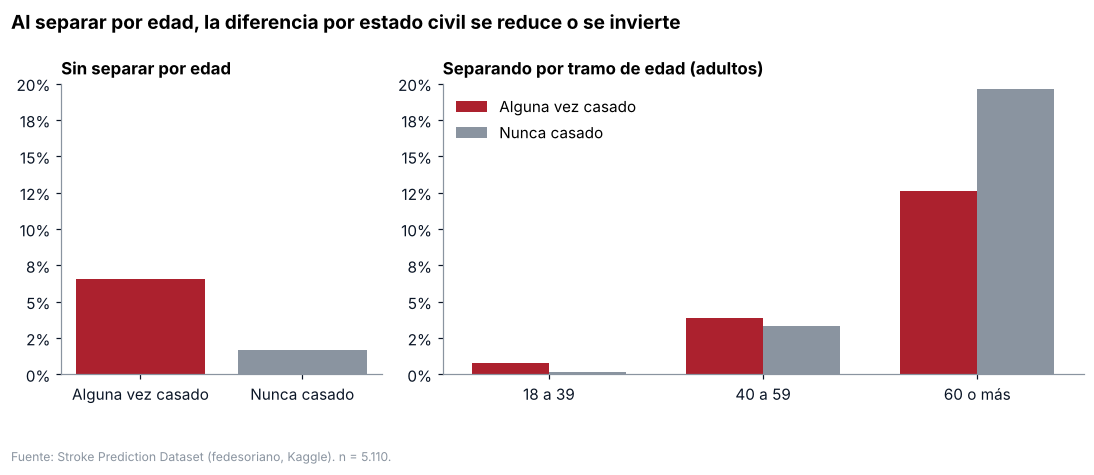

Sin separar: 6,6 % frente a 1,7 % (4.0 veces)


casado,Alguna vez casado,Nunca casado
tramo,,
18 a 39,0.007,0.002
40 a 59,0.039,0.033
60 o más,0.126,0.196


In [13]:
legible["casado"] = legible["ever_married"].map({"Yes": "Alguna vez casado", "No": "Nunca casado"})
cruda_casado = legible.groupby("casado")[OBJETIVO].mean()
estratos_casado = (legible[legible["age"] >= 18]
                   .assign(tramo=lambda d: pd.cut(d["age"], [18, 40, 60, 120], right=False,
                                                  labels=["18 a 39", "40 a 59", "60 o más"]))
                   .groupby(["tramo", "casado"], observed=True)[OBJETIVO].mean().unstack())

fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 2]})
izq.bar(cruda_casado.index, cruda_casado.values, color=[GRANATE, GRIS])
izq.set_title("Sin separar por edad", fontsize=11)
porcentaje(izq.yaxis)
izq.set_ylim(0, 0.2)
x = np.arange(len(estratos_casado.index))
der.bar(x - 0.18, estratos_casado["Alguna vez casado"], width=0.36, color=GRANATE, label="Alguna vez casado")
der.bar(x + 0.18, estratos_casado["Nunca casado"], width=0.36, color=GRIS, label="Nunca casado")
der.set_xticks(x, estratos_casado.index.astype(str))
der.set_title("Separando por tramo de edad (adultos)", fontsize=11)
porcentaje(der.yaxis)
der.set_ylim(0, 0.2)
der.legend(loc="upper left")
fig.suptitle("Al separar por edad, la diferencia por estado civil se reduce o se invierte",
             x=0.01, ha="left", fontweight="bold", fontsize=12.5)
nota_fuente(fig)
figuras["fig6_asociacion_espuria"] = fig
plt.tight_layout()
plt.show()

print(f"Sin separar: {pct(cruda_casado['Alguna vez casado'], 1)} frente a {pct(cruda_casado['Nunca casado'], 1)} "
      f"({cruda_casado['Alguna vez casado'] / cruda_casado['Nunca casado']:.1f} veces)")
estratos_casado.round(3)

**Lectura.** Mirado en bruto, haber estado casado parece cuadruplicar la tasa de ACV. Es
un ejemplo de manual de **variable de confusión**: los menores de edad nunca se han casado
y casi no presentan ACV, y entre los adultos las personas casadas son mayores. Al comparar
dentro de cada tramo de edad, la diferencia se reduce o se invierte. Esta figura no va al
informe como hallazgo, sino como evidencia de que el equipo controló la confusión antes de
afirmar una asociación.

---
## 4. Una figura que miente, y cómo corregirla

El mismo dato puede contarse de forma honesta o engañosa. El caso más frecuente es el eje
truncado: al empezar el eje en un valor distinto de cero, una diferencia pequeña parece
enorme. El **factor de mentira** de Tufte lo cuantifica: el tamaño del efecto mostrado
dividido por el tamaño del efecto real. Una figura honesta tiene un factor cercano a 1.

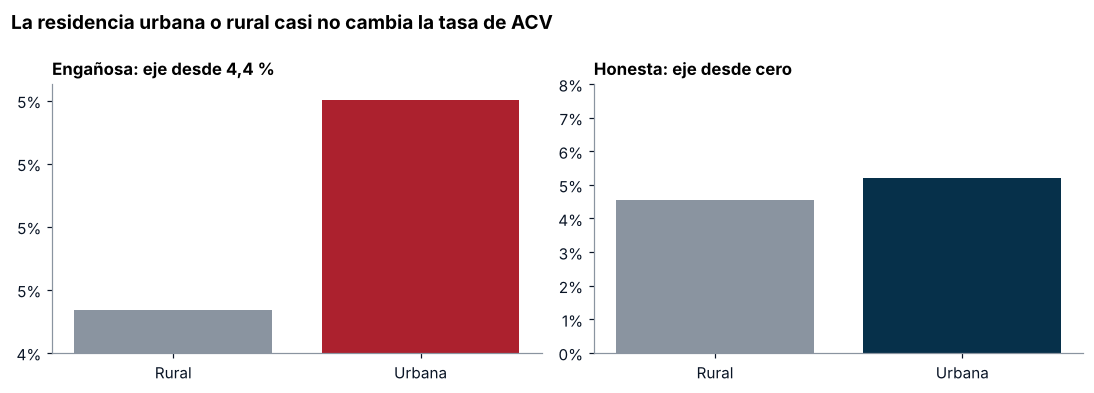

Diferencia real      : 14,7 %
Diferencia aparente  : 495 %
Factor de mentira    : 34


In [14]:
tasas_residencia = com.tasa_por_grupo(legible, "Residence_type", OBJETIVO)
etiquetas = tasas_residencia["Residence_type"].map({"Rural": "Rural", "Urban": "Urbana"})
valores = tasas_residencia["tasa"].to_numpy()
piso = 0.044

fig, (mal, bien) = plt.subplots(1, 2, figsize=(10, 3.6))
mal.bar(etiquetas, valores, color=[GRIS, GRANATE])
mal.set_ylim(piso, valores.max() * 1.01)
mal.set_title("Engañosa: eje desde 4,4 %", fontsize=11)
porcentaje(mal.yaxis)
bien.bar(etiquetas, valores, color=[GRIS, AZUL])
bien.set_ylim(0, 0.08)
bien.set_title("Honesta: eje desde cero", fontsize=11)
porcentaje(bien.yaxis)
fig.suptitle("La residencia urbana o rural casi no cambia la tasa de ACV", x=0.01, ha="left",
             fontweight="bold", fontsize=12.5)
plt.tight_layout()
plt.show()

efecto_real = valores.max() / valores.min() - 1
efecto_mostrado = (valores.max() - piso) / (valores.min() - piso) - 1
print(f"Diferencia real      : {pct(efecto_real, 1)}")
print(f"Diferencia aparente  : {pct(efecto_mostrado, 0)}")
print(f"Factor de mentira    : {efecto_mostrado / efecto_real:.0f}")

---
## 5. Eficiencia: construir la copia interpretable

La Fase 3 midió el costo de sus transformaciones. Aquí se aplica la misma idea a la única
operación nueva de esta fase, revertir el escalamiento, comparando un recorrido fila por
fila con la operación vectorizada. Se usa la función `medir` de `src/medicion.py`, la misma
de la Fase 3.

In [15]:
def revertir_fila_por_fila(df, parametros):
    """Versión ingenua: recorre cada fila y cada columna en Python. Costo O(n · k)."""
    resultado = df.copy()
    for paso, valores in parametros.items():
        if paso.startswith("EscaladorEstandar("):
            columna = paso[len("EscaladorEstandar("):-1]
            resultado[columna] = [z * valores["desviacion"] + valores["media"] for z in resultado[columna]]
    return resultado


ingenua, t_ingenua, m_ingenua = medir(revertir_fila_por_fila, entrenamiento, parametros)
vectorizada, t_vector, m_vector = medir(com.revertir_escalamiento, entrenamiento, parametros)

pd.testing.assert_frame_equal(ingenua, vectorizada)   # mismo resultado, distinto costo
print(f"Fila por fila : {t_ingenua * 1000:8.2f} ms   pico {m_ingenua:6.2f} MB")
print(f"Vectorizada   : {t_vector * 1000:8.2f} ms   pico {m_vector:6.2f} MB")
print(f"La vectorizada es {t_ingenua / t_vector:.0f} veces más rápida, con el mismo resultado.")

Fila por fila :    24.70 ms   pico   1.99 MB
Vectorizada   :     3.15 ms   pico   1.99 MB
La vectorizada es 8 veces más rápida, con el mismo resultado.


Ambas versiones tienen complejidad lineal en el número de filas, pero la vectorizada
ejecuta el recorrido en código compilado de NumPy en vez de en el intérprete de Python. Con
4.088 filas la diferencia es de milisegundos; con millones de registros sería la diferencia
entre segundos y minutos.

---
## 6. Validación técnica

Tres escenarios, como pide el descriptor: casos normales, casos límite y excepciones. Cada
control queda registrado en una tabla, que es la evidencia que se cita en el informe.

In [16]:
controles = []


def verificar(escenario, control, condicion, detalle=""):
    controles.append({"escenario": escenario, "control": control,
                      "estado": "OK" if condicion else "FALLA", "detalle": detalle})


# Casos normales
verificar("normal", "La copia conserva las filas", len(entrenamiento_legible) == len(entrenamiento),
          f"{len(entrenamiento_legible)} filas")
verificar("normal", "La edad revertida tiene la media aprendida",
          np.isclose(entrenamiento_legible["age"].mean(), parametros["EscaladorEstandar(age)"]["media"]),
          f"{entrenamiento_legible['age'].mean():.2f} años")
verificar("normal", "Las tasas por tramo suman los casos totales",
          int(tasas_edad["casos"].sum()) == casos, f"{casos} casos")

# Casos límite
verificar("límite", "Edad mínima dentro del rango original",
          legible["age"].min() >= original["age"].min() - 1e-9, f"{legible['age'].min():.2f}")
verificar("límite", "Intervalo de Wilson sin casos no es negativo",
          com.intervalo_wilson(0, 22)[0] == 0.0, "Never_worked: 0 de 22")
verificar("límite", "Intervalo de Wilson con todos los casos no supera 1",
          com.intervalo_wilson(10, 10)[1] <= 1.0)

# Excepciones
try:
    com.cargar_artefactos(RAIZ / "carpeta_inexistente")
    verificar("excepción", "Falta un artefacto", False, "no lanzó error")
except FileNotFoundError:
    verificar("excepción", "Falta un artefacto", True, "FileNotFoundError")

try:
    com.leer_parametros(pd.DataFrame([{"paso": "EscaladorEstandar(age)", "parametros": "media=1"}]))
    verificar("excepción", "Parámetros ilegibles", False, "no lanzó error")
except ValueError:
    verificar("excepción", "Parámetros ilegibles", True, "ValueError")

try:
    com.intervalo_wilson(0, 0)
    verificar("excepción", "Proporción sin observaciones", False, "no lanzó error")
except ValueError:
    verificar("excepción", "Proporción sin observaciones", True, "ValueError")

tabla_controles = pd.DataFrame(controles)
assert (tabla_controles["estado"] == "OK").all(), "Hay controles que fallaron"
tabla_controles

,escenario,control,estado,detalle
0,normal,La copia conserva las filas,OK,4088 filas
1,normal,La edad revertida tiene la media aprendida,OK,43.46 años
2,normal,Las tasas por tramo suman los casos totales,OK,249 casos
3,límite,Edad mínima dentro del rango original,OK,0.08
4,límite,Intervalo de Wilson sin casos no es negativo,OK,Never_worked: 0 de 22
5,límite,Intervalo de Wilson con todos los casos no sup...,OK,
6,excepción,Falta un artefacto,OK,FileNotFoundError
7,excepción,Parámetros ilegibles,OK,ValueError
8,excepción,Proporción sin observaciones,OK,ValueError


---
## 7. Persistencia: lo que se lleva al informe y al video

Las figuras se guardan en `F4/figuras/` a 200 ppp, resolución suficiente para el informe
impreso. Los hallazgos se guardan en `docs/hallazgos_f4.csv`, con la cifra exacta que los
respalda: así el texto del informe y el del video se escriben desde la misma fuente.

In [17]:
rutas = {nombre: com.guardar_figura(figura, DIR_FIGURAS, nombre) for nombre, figura in figuras.items()}

hallazgos = pd.DataFrame([
    {"figura": "fig1_clase_positiva", "hallazgo": "La clase positiva es escasa",
     "evidencia": f"{pct(tasa_global, 2)} de ACV ({casos} de {total})"},
    {"figura": "fig2_faltantes_imc", "hallazgo": "Los faltantes de IMC no son aleatorios",
     "evidencia": f"{pct(tasas_imc.set_index('imc_registrado').loc['IMC faltante', 'tasa'], 1)} de ACV sin IMC frente a "
                  f"{pct(tasas_imc.set_index('imc_registrado').loc['IMC registrado', 'tasa'], 1)} con IMC"},
    {"figura": "fig3_edad", "hallazgo": "La edad es el factor con mayor asociación",
     "evidencia": f"{pct(tasas_edad['tasa'].iloc[0], 1)} entre 0 y 17 años frente a {pct(tasas_edad['tasa'].iloc[-1], 1)} desde los 80"},
    {"figura": "fig4_hipertension_por_edad", "hallazgo": "La hipertensión se asocia al ACV a igual edad",
     "evidencia": f"Bruto {pct(cruda['Con hipertensión'], 1)} frente a {pct(cruda['Sin hipertensión'], 1)}; la diferencia persiste en ambos grupos de edad"},
    {"figura": "fig5_glucosa", "hallazgo": "La glucosa en rango de diabetes casi triplica la tasa",
     "evidencia": f"{pct(tasas_glucosa['tasa'].iloc[-1], 1)} frente a {pct(tasas_glucosa['tasa'].iloc[0], 1)} con glucosa normal"},
    {"figura": "fig6_asociacion_espuria", "hallazgo": "El estado civil es una asociación espuria",
     "evidencia": "La diferencia bruta se reduce o invierte al separar por edad"},
])
hallazgos.to_csv(DIR_DOCS / "hallazgos_f4.csv", index=False)

metadatos = {
    "fase": "F4",
    "fecha_ejecucion": date.today().isoformat(),
    "semilla": SEMILLA,
    "python": sys.version.split()[0],
    "dependencias": {"numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
    "entradas": [str((DIR_PROCESADO / a).relative_to(RAIZ)) for a in com.ARTEFACTOS_F3.values()],
    "figuras": [str(Path(r).relative_to(RAIZ)) for r in rutas.values()],
    "controles_superados": int((tabla_controles["estado"] == "OK").sum()),
}
with open(DIR_DOCS / "metadatos_f4.json", "w", encoding="utf-8") as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)

for nombre, ruta in rutas.items():
    print(f"{nombre:<28} {Path(ruta).relative_to(RAIZ)}  ({os.path.getsize(ruta) / 1024:.0f} KB)")
print("\nHallazgos  :", (DIR_DOCS / "hallazgos_f4.csv").relative_to(RAIZ))
print("Metadatos  :", (DIR_DOCS / "metadatos_f4.json").relative_to(RAIZ))
hallazgos

fig1_clase_positiva          F4/figuras/fig1_clase_positiva.png  (67 KB)
fig2_faltantes_imc           F4/figuras/fig2_faltantes_imc.png  (76 KB)
fig3_edad                    F4/figuras/fig3_edad.png  (111 KB)
fig4_hipertension_por_edad   F4/figuras/fig4_hipertension_por_edad.png  (89 KB)
fig5_glucosa                 F4/figuras/fig5_glucosa.png  (93 KB)
fig6_asociacion_espuria      F4/figuras/fig6_asociacion_espuria.png  (113 KB)

Hallazgos  : docs/hallazgos_f4.csv
Metadatos  : docs/metadatos_f4.json


,figura,hallazgo,evidencia
0,fig1_clase_positiva,La clase positiva es escasa,"4,87 % de ACV (249 de 5110)"
1,fig2_faltantes_imc,Los faltantes de IMC no son aleatorios,"19,9 % de ACV sin IMC frente a 4,3 % con IMC"
2,fig3_edad,La edad es el factor con mayor asociación,"0,2 % entre 0 y 17 años frente a 21,5 % desde ..."
3,fig4_hipertension_por_edad,La hipertensión se asocia al ACV a igual edad,"Bruto 13,3 % frente a 4,0 %; la diferencia per..."
4,fig5_glucosa,La glucosa en rango de diabetes casi triplica ...,"10,2 % frente a 3,6 % con glucosa normal"
5,fig6_asociacion_espuria,El estado civil es una asociación espuria,La diferencia bruta se reduce o invierte al se...


---
## 8. El relato en tres actos

El informe y el video cuentan lo mismo, en este orden:

**Acto 1 · El problema.** El accidente cerebrovascular es frecuente en la población adulta
y en este conjunto afecta al 4,9 % de las personas. La pregunta es qué características
acompañan al evento (figura 1).

**Acto 2 · Lo que muestran los datos.** La edad es el factor dominante (figura 3). La
hipertensión y la glucosa en rango de diabetes se asocian a tasas mayores, y en el caso de
la hipertensión la asociación resiste el control por edad (figuras 4 y 5).

**Acto 3 · Lo que no se puede afirmar.** Son asociaciones en datos observacionales y
secundarios, no causas. Algunas asociaciones aparentes, como la del estado civil, las
explica la edad (figura 6). Y la imputación del IMC borró una señal relevante (figura 2),
que queda como mejora para una versión siguiente del pipeline.

### Limitaciones que el informe debe declarar

1. Los datos son secundarios: no se controló su recolección ni su representatividad.
2. La clase positiva es escasa, por lo que las tasas de grupos pequeños son inestables.
3. La glucosa es un promedio, no una medición en ayunas.
4. La imputación del IMC con la mediana ocultó que los faltantes se asocian al evento.
5. Asociación no es causalidad: ninguna figura demuestra un efecto.

---
## 9. Su turno: ejercicios para el proyecto

Resuélvanlos con **su propio conjunto de datos**. Cada uno produce evidencia que pide la
rúbrica de la Fase 4.

### Ejercicio 1 · Cargar sus artefactos y verificar el contrato

Adapten la carga a los nombres de los archivos que dejó su Fase 3 y escriban al menos
tres `assert` sobre el esquema, los nulos y el escalamiento.

In [18]:
# TODO: ajusten la carpeta y los nombres si su Fase 3 usó otros
# mis_artefactos = com.cargar_artefactos(DIR_PROCESADO)

# TODO: tres comprobaciones del contrato
# assert ...
# assert ...
# assert ...

### Ejercicio 2 · Una figura por objetivo específico

Escriban la tabla que vincula cada objetivo de su Fase 1 con la figura que lo responde.
Si un objetivo queda sin figura, el trabajo está incompleto.

In [19]:
# TODO: completar con sus objetivos y figuras
mi_vinculacion = pd.DataFrame([
    # {"objetivo": "...", "pregunta": "...", "figura": "fig1_...", "hallazgo": "..."},
])
mi_vinculacion

""


### Ejercicio 3 · Un título que dice el hallazgo

Tomen una de sus figuras y cambien un título descriptivo («Distribución de X por Y») por
uno que diga lo que se ve («X es el doble en Y que en Z»). Agreguen el tamaño de cada grupo.

In [20]:
# TODO: su figura con título que comunica
# fig, ax = plt.subplots()
# ...
# ax.set_title("...")
# plt.show()

### Ejercicio 4 · Controlar una variable de confusión

Elijan la asociación más fuerte de su proyecto y repítanla separando por la variable que
podría explicarla. Expliquen si la asociación se mantiene, se reduce o se invierte.

In [21]:
# TODO: comparación bruta y estratificada
# bruta = mis_datos.groupby("...")["..."].mean()
# estratificada = mis_datos.groupby(["...", "..."])["..."].mean().unstack()

### Ejercicio 5 · Guardar y documentar

Guarden sus figuras con `com.guardar_figura` y su tabla de hallazgos en `docs/`. Antes de
entregar, ejecuten el cuaderno con **Restart Kernel and Run All** y comprueben que no queda
ninguna celda con error.

In [22]:
# TODO: persistencia de sus figuras y hallazgos
# for nombre, figura in mis_figuras.items():
#     com.guardar_figura(figura, DIR_FIGURAS, nombre)